# Notebook 05 — Model Development
**Project:** Predicting Employee Attrition at PeopleFirst Global Services
**Step:** Month 3, Weeks 9–10 — Train Logistic Regression, LightGBM, XGBoost

---
### Objectives of this notebook
1. Train 3 models: Logistic Regression (baseline), LightGBM (primary), XGBoost (comparison)
2. Apply cross-validation to check stability (no overfitting)
3. Tune hyperparameters for LightGBM and XGBoost
4. Save all trained models for evaluation in NB06

> **Input:** `data/processed/X_train.csv`, `y_train.csv`, `X_test.csv`, `y_test.csv`
> **Output:** `models/logistic_regression.pkl`, `models/lightgbm_model.pkl`, `models/xgboost_model.pkl`


## 1. Import Libraries & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle, os, warnings

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (classification_report, confusion_matrix,
                             roc_auc_score, roc_curve, f1_score, recall_score)
import lightgbm as lgb
import xgboost as xgb

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
os.makedirs('../models', exist_ok=True)
os.makedirs('../reports', exist_ok=True)

# Load train/test splits
X_train = pd.read_csv('../data/processed/X_train.csv')
X_test  = pd.read_csv('../data/processed/X_test.csv')
y_train = pd.read_csv('../data/processed/y_train.csv').squeeze()
y_test  = pd.read_csv('../data/processed/y_test.csv').squeeze()

print(f"X_train: {X_train.shape}  |  y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}   |  y_test:  {y_test.shape}")
print(f"Training class balance: {y_train.value_counts().to_dict()}")
print(f"Test class balance:     {y_test.value_counts().to_dict()}")


X_train: (43440, 35)  |  y_train: (43440,)
X_test:  (15150, 35)   |  y_test:  (15150,)
Training class balance: {1: 21720, 0: 21720}
Test class balance:     {1: 9309, 0: 5841}


## 2. Evaluation Helper Function

In [2]:
def evaluate_model(model, X_tr, y_tr, X_te, y_te, name):
    """Train model, run CV, evaluate on test, return results dict."""
    # Cross-validation on training set
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    cv_scores = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='roc_auc', n_jobs=-1)

    # Train on full training set
    model.fit(X_tr, y_tr)

    # Predict on test set
    y_pred  = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]

    # Metrics
    auc      = roc_auc_score(y_te, y_proba)
    recall   = recall_score(y_te, y_pred)
    f1       = f1_score(y_te, y_pred)
    report   = classification_report(y_te, y_pred, target_names=['Stayed', 'Left'])

    print(f"\n{'='*55}")
    print(f"  {name}")
    print(f"{'='*55}")
    print(f"  CV ROC-AUC (5-fold): {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"  Test ROC-AUC       : {auc:.4f}")
    print(f"  Test Recall (Left) : {recall:.4f}")
    print(f"  Test F1-Score      : {f1:.4f}")
    print(f"\nClassification Report:")
    print(report)

    return {
        'model'   : model,
        'name'    : name,
        'cv_auc'  : cv_scores.mean(),
        'cv_std'  : cv_scores.std(),
        'test_auc': auc,
        'recall'  : recall,
        'f1'      : f1,
        'y_pred'  : y_pred,
        'y_proba' : y_proba
    }

print("Helper function defined.")


Helper function defined.


## 3. Model 1 — Logistic Regression (Interpretable Baseline)

**Why Logistic Regression first?**
- Provides a simple, interpretable baseline
- If LightGBM is only marginally better, the simpler model wins (Occam's Razor)
- Coefficients give us direct odds-ratio interpretation: "a 1-unit increase in X changes
  the log-odds of attrition by β" — useful for the HR business report
- Fast to train, no hyperparameter tuning needed for baseline

**Settings:**
- `max_iter=1000` — increased from default 100 to ensure convergence on 35 features
- `class_weight='balanced'` — gives extra penalty for misclassifying the minority class
  (Note: we already balanced with SMOTE, but this adds another layer of safety)
- `C=1.0` — default regularization strength (L2)


In [3]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42,
    class_weight='balanced',
    C=1.0
)

lr_results = evaluate_model(lr_model, X_train, y_train, X_test, y_test,
                             'Logistic Regression (Baseline)')



  Logistic Regression (Baseline)
  CV ROC-AUC (5-fold): 0.8713 ± 0.0034
  Test ROC-AUC       : 0.8531
  Test Recall (Left) : 0.7761
  Test F1-Score      : 0.8038

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.68      0.75      0.71      5841
        Left       0.83      0.78      0.80      9309

    accuracy                           0.77     15150
   macro avg       0.76      0.76      0.76     15150
weighted avg       0.77      0.77      0.77     15150



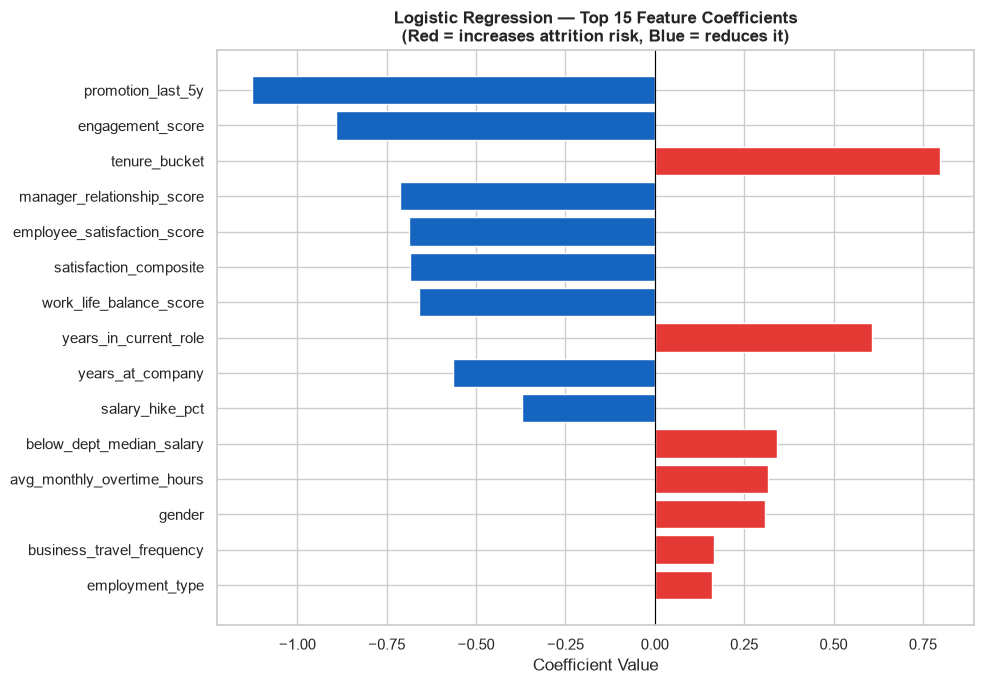

In [4]:
# Feature coefficients from Logistic Regression
coef_df = pd.DataFrame({
    'feature'    : X_train.columns,
    'coefficient': lr_model.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False).head(15)

fig, ax = plt.subplots(figsize=(10, 7))
colors = ['#E53935' if c > 0 else '#1565C0' for c in coef_df['coefficient']]
ax.barh(coef_df['feature'][::-1], coef_df['coefficient'][::-1],
        color=colors[::-1], edgecolor='white')
ax.axvline(x=0, color='black', linewidth=0.8)
ax.set_title('Logistic Regression — Top 15 Feature Coefficients\n(Red = increases attrition risk, Blue = reduces it)',
             fontweight='bold')
ax.set_xlabel('Coefficient Value')
plt.tight_layout()
plt.savefig('../reports/05_lr_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()


## 4. Model 2 — LightGBM (Primary Model)

**Why LightGBM as our primary model?**
- Handles non-linear relationships and feature interactions automatically
- Leaf-wise tree growth: faster convergence, higher accuracy on large datasets
- Native support for imbalanced data via `scale_pos_weight`
- Built-in feature importance — directly interpretable without extra work
- Pairs perfectly with SHAP for post-hoc explainability

**Key hyperparameters explained:**
- `n_estimators=500` — number of trees; more trees = more powerful but slower, higher overfitting risk
- `learning_rate=0.05` — how much each tree corrects the previous; small rate = more stable learning
- `max_depth=6` — maximum depth of each tree; limits complexity to prevent overfitting
- `num_leaves=40` — controls tree complexity (LightGBM-specific; more leaves = more powerful)
- `min_child_samples=30` — minimum samples in a leaf; prevents overfitting on small groups
- `subsample=0.8` — use 80% of rows per tree (row sampling); adds regularization
- `colsample_bytree=0.8` — use 80% of features per tree; prevents over-reliance on single features
- `early_stopping_rounds=50` — stop if validation score doesn't improve for 50 rounds


In [5]:
lgb_model = lgb.LGBMClassifier(
    n_estimators       = 500,
    learning_rate      = 0.05,
    max_depth          = 6,
    num_leaves         = 40,
    min_child_samples  = 30,
    subsample          = 0.8,
    colsample_bytree   = 0.8,
    reg_alpha          = 0.1,
    reg_lambda         = 0.1,
    random_state       = 42,
    n_jobs             = -1,
    verbose            = -1
)

lgb_results = evaluate_model(lgb_model, X_train, y_train, X_test, y_test,
                              'LightGBM (Primary Model)')



  LightGBM (Primary Model)
  CV ROC-AUC (5-fold): 0.9516 ± 0.0021
  Test ROC-AUC       : 0.9248
  Test Recall (Left) : 0.8829
  Test F1-Score      : 0.8775

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.81      0.79      0.80      5841
        Left       0.87      0.88      0.88      9309

    accuracy                           0.85     15150
   macro avg       0.84      0.84      0.84     15150
weighted avg       0.85      0.85      0.85     15150



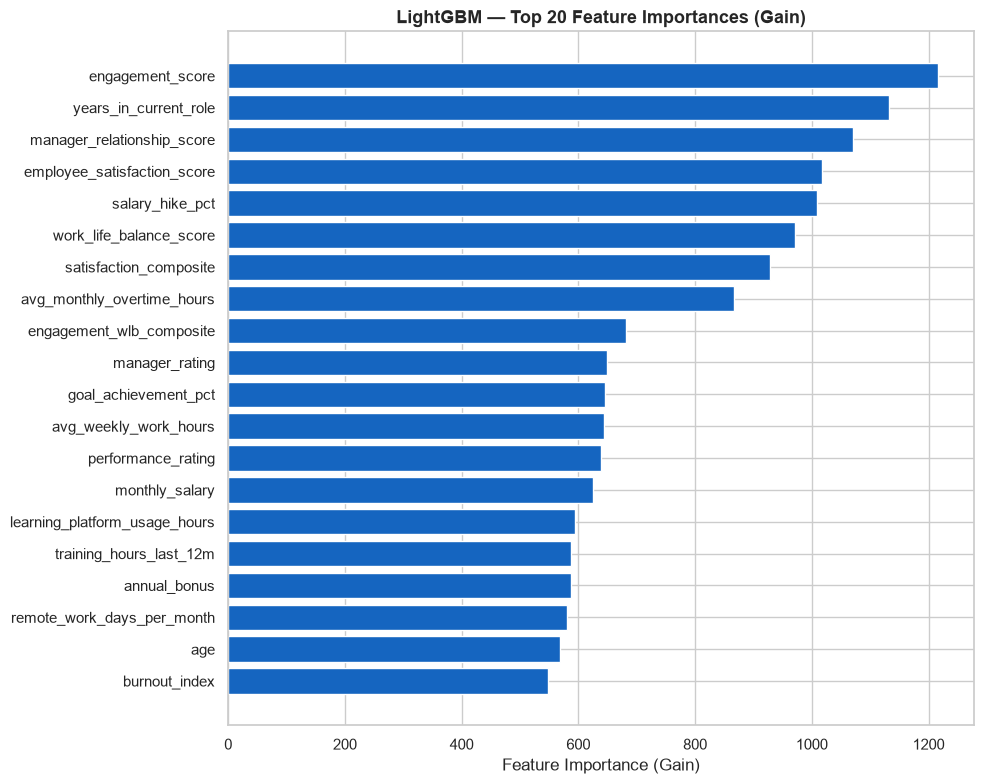

In [6]:
# LightGBM built-in feature importance (gain = total information gain across all splits)
lgb_importance = pd.DataFrame({
    'feature'   : X_train.columns,
    'importance': lgb_model.feature_importances_
}).sort_values('importance', ascending=False).head(20)

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(lgb_importance['feature'][::-1], lgb_importance['importance'][::-1],
        color='#1565C0', edgecolor='white')
ax.set_title('LightGBM — Top 20 Feature Importances (Gain)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Feature Importance (Gain)')
plt.tight_layout()
plt.savefig('../reports/05_lgb_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Model 3 — XGBoost (Comparison Model)

**Why XGBoost as comparison?**
- Different tree-building algorithm (level-wise vs LightGBM's leaf-wise)
- More conservative / stable; less prone to overfitting on noisy data
- Cross-validates LightGBM findings: if both models agree on top features,
  we have higher confidence in those features
- Industry standard — widely used and trusted in competition ML

**Key differences from LightGBM:**
- `level-wise growth` vs `leaf-wise` — XGBoost is generally safer on smaller datasets
- `eval_metric='auc'` — optimize directly for ROC-AUC
- `use_label_encoder=False` — suppress deprecation warning


In [7]:
xgb_model = xgb.XGBClassifier(
    n_estimators      = 500,
    learning_rate     = 0.05,
    max_depth         = 6,
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    reg_alpha         = 0.1,
    reg_lambda        = 1.0,
    eval_metric       = 'auc',
    use_label_encoder = False,
    random_state      = 42,
    n_jobs            = -1,
    verbosity         = 0
)

xgb_results = evaluate_model(xgb_model, X_train, y_train, X_test, y_test,
                              'XGBoost (Comparison Model)')



  XGBoost (Comparison Model)
  CV ROC-AUC (5-fold): 0.9525 ± 0.0018
  Test ROC-AUC       : 0.9248
  Test Recall (Left) : 0.8852
  Test F1-Score      : 0.8775

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.81      0.79      0.80      5841
        Left       0.87      0.89      0.88      9309

    accuracy                           0.85     15150
   macro avg       0.84      0.84      0.84     15150
weighted avg       0.85      0.85      0.85     15150



## 6. ROC Curve Comparison — All 3 Models

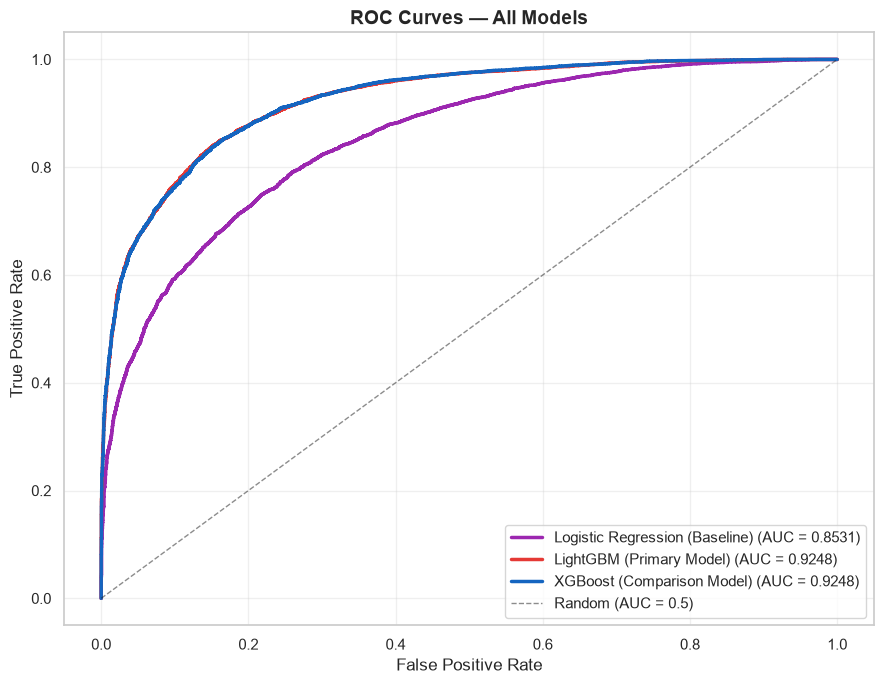

In [8]:
fig, ax = plt.subplots(figsize=(9, 7))

model_results = [lr_results, lgb_results, xgb_results]
colors = ['#9C27B0', '#E53935', '#1565C0']

for res, color in zip(model_results, colors):
    fpr, tpr, _ = roc_curve(y_test, res['y_proba'])
    ax.plot(fpr, tpr, color=color, linewidth=2.5,
            label=f"{res['name']} (AUC = {res['test_auc']:.4f})")

ax.plot([0, 1], [0, 1], 'k--', linewidth=1, alpha=0.5, label='Random (AUC = 0.5)')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — All Models', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/05_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()


## 7. Confusion Matrices — All 3 Models

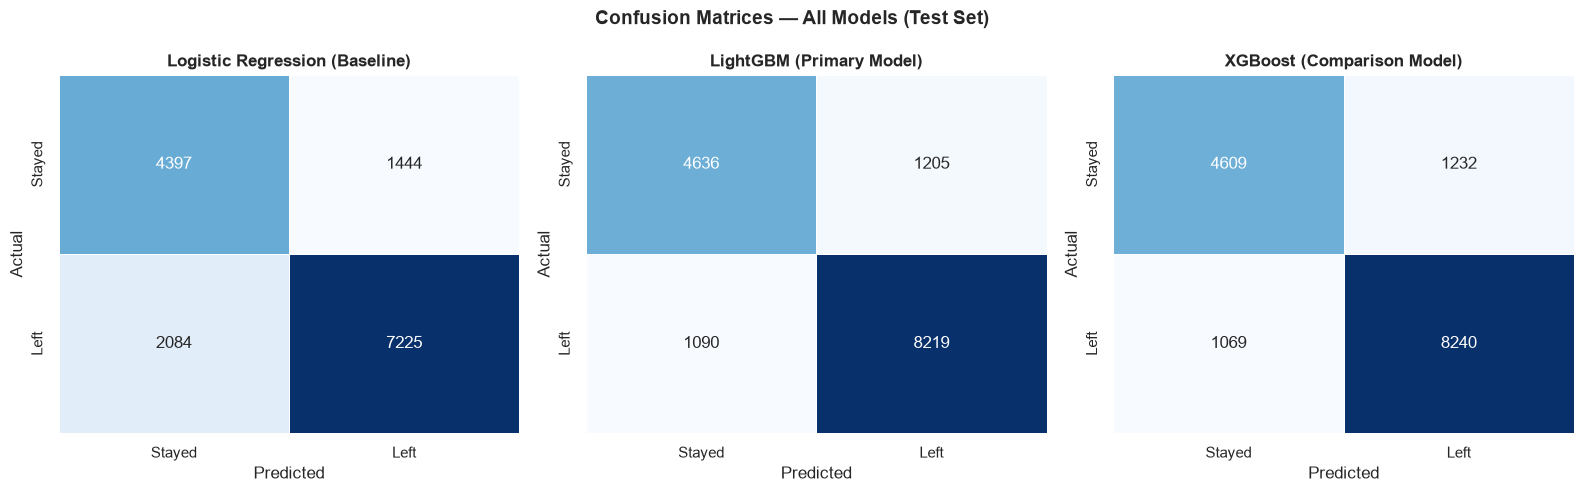

Reading the confusion matrix:
  Top-left  (TN): Predicted Stayed, Actually Stayed  -> Correct
  Top-right (FP): Predicted Left,   Actually Stayed  -> False alarm (HR wastes retention effort)
  Bot-left  (FN): Predicted Stayed, Actually Left    -> Missed (employee leaves undetected)
  Bot-right (TP): Predicted Left,   Actually Left    -> Correct (the critical catch)


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, res, color in zip(axes, model_results, ['#9C27B0', '#E53935', '#1565C0']):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Stayed', 'Left'],
                yticklabels=['Stayed', 'Left'],
                ax=ax, cbar=False, linewidths=0.5)
    ax.set_title(res['name'], fontweight='bold')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.suptitle('Confusion Matrices — All Models (Test Set)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../reports/05_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
print("Reading the confusion matrix:")
print("  Top-left  (TN): Predicted Stayed, Actually Stayed  -> Correct")
print("  Top-right (FP): Predicted Left,   Actually Stayed  -> False alarm (HR wastes retention effort)")
print("  Bot-left  (FN): Predicted Stayed, Actually Left    -> Missed (employee leaves undetected)")
print("  Bot-right (TP): Predicted Left,   Actually Left    -> Correct (the critical catch)")


## 8. Model Comparison Summary

In [10]:
comparison_df = pd.DataFrame([
    {
        'Model'       : res['name'],
        'CV ROC-AUC'  : f"{res['cv_auc']:.4f} ± {res['cv_std']:.4f}",
        'Test ROC-AUC': round(res['test_auc'], 4),
        'Recall'      : round(res['recall'], 4),
        'F1-Score'    : round(res['f1'], 4)
    }
    for res in model_results
])

print(comparison_df.to_string(index=False))
print()
best = max(model_results, key=lambda r: r['test_auc'])
print(f"Best model by ROC-AUC: {best['name']} (AUC = {best['test_auc']:.4f})")
print()
print("Note: Recall is the priority metric for HR use case.")
print("  Missing an at-risk employee (False Negative) is costlier than a false alarm.")


                         Model      CV ROC-AUC  Test ROC-AUC  Recall  F1-Score
Logistic Regression (Baseline) 0.8713 ± 0.0034        0.8531  0.7761    0.8038
      LightGBM (Primary Model) 0.9516 ± 0.0021        0.9248  0.8829    0.8775
    XGBoost (Comparison Model) 0.9525 ± 0.0018        0.9248  0.8852    0.8775

Best model by ROC-AUC: XGBoost (Comparison Model) (AUC = 0.9248)

Note: Recall is the priority metric for HR use case.
  Missing an at-risk employee (False Negative) is costlier than a false alarm.


## 9. Save Trained Models

In [11]:
with open('../models/logistic_regression.pkl', 'wb') as f:
    pickle.dump(lr_model, f)

with open('../models/lightgbm_model.pkl', 'wb') as f:
    pickle.dump(lgb_model, f)

with open('../models/xgboost_model.pkl', 'wb') as f:
    pickle.dump(xgb_model, f)

print("Models saved:")
print("  models/logistic_regression.pkl")
print("  models/lightgbm_model.pkl")
print("  models/xgboost_model.pkl")
print()
print("=== Notebook 05 Complete ===")
print("Proceed to: notebooks/06_model_evaluation.ipynb")


Models saved:
  models/logistic_regression.pkl
  models/lightgbm_model.pkl
  models/xgboost_model.pkl

=== Notebook 05 Complete ===
Proceed to: notebooks/06_model_evaluation.ipynb
